Các thư viện bổ sung sau đây là cần thiết để chạy notebook này. Lưu ý rằng việc chạy trên Colab vẫn đang trong quá trình thử nghiệm, vui lòng báo cáo lỗi trên Github nếu bạn gặp bất kỳ vấn đề nào.

In [ ]:
# Cài đặt thư viện d2l phiên bản 1.0.3
!pip install d2l==1.0.3 --no-deps

# Độ ổn định số học và Khởi tạo tham số
:label:`sec_numerical_stability`

Cho đến nay, mọi mô hình mà chúng ta đã triển khai đều yêu cầu chúng ta khởi tạo các tham số của nó theo một phân phối xác định trước nào đó. Từ trước đến nay, chúng ta đã coi sơ đồ khởi tạo là điều hiển nhiên, lướt qua các chi tiết về cách đưa ra những lựa chọn này. Bạn thậm chí có thể có ấn tượng rằng những lựa chọn này không đặc biệt quan trọng. Trái lại, việc lựa chọn sơ đồ khởi tạo đóng một vai trò quan trọng trong việc học của mạng thần kinh nhân tạo và nó có thể mang tính quyết định để duy trì sự ổn định số học. Hơn nữa, những lựa chọn này có thể liên kết chặt chẽ theo những cách thú vị với việc lựa chọn hàm kích hoạt phi tuyến tính.

Hàm kích hoạt nào chúng ta chọn và cách chúng ta khởi tạo các tham số có thể quyết định tốc độ hội tụ của thuật toán tối ưu hóa. Những lựa chọn tồi ở đây có thể khiến chúng ta gặp phải hiện tượng bùng nổ hoặc tiêu biến gradient (exploding/vanishing gradients) trong quá trình huấn luyện. Trong phần này, chúng ta sẽ đi sâu vào các chủ đề này một cách chi tiết hơn và thảo luận về một số phương pháp phỏng đoán (heuristics) hữu ích mà bạn sẽ thấy giá trị trong suốt sự nghiệp học sâu của mình.

In [ ]:
%matplotlib inline
import torch
from d2l import torch as d2l
# Nhập thư viện PyTorch và module hỗ trợ d2l để vẽ đồ thị và xử lý dữ liệu

## Tiêu biến và Bùng nổ Gradient (Vanishing and Exploding Gradients)

Xét một mạng sâu có $L$ lớp, đầu vào $\mathbf{x}$ và đầu ra $\mathbf{o}$. Với mỗi lớp $l$ được định nghĩa bởi một phép biến đổi $f_l$ được tham số hóa bởi trọng số $\mathbf{W}^{(l)}$, có đầu ra lớp ẩn là $\mathbf{h}^{(l)}$ (giả sử $\mathbf{h}^{(0)} = \mathbf{x}$), mạng của chúng ta có thể được biểu diễn như sau:

$$\mathbf{h}^{(l)} = f_l (\mathbf{h}^{(l-1)}) \textrm{ và do đó } \mathbf{o} = f_L \circ \cdots \circ f_1(\mathbf{x}).$$

Nếu tất cả đầu ra lớp ẩn và đầu vào đều là các vector, chúng ta có thể viết gradient của $\mathbf{o}$ đối với bất kỳ tập hợp tham số $\mathbf{W}^{(l)}$ nào như sau:

$$\partial_{\mathbf{W}^{(l)}} \mathbf{o} = \underbrace{\partial_{\mathbf{h}^{(L-1)}} \mathbf{h}^{(L)}}_{ \mathbf{M}^{(L)} \stackrel{\textrm{def}}{=}} \cdots \underbrace{\partial_{\mathbf{h}^{(l)}} \mathbf{h}^{(l+1)}}_{ \mathbf{M}^{(l+1)} \stackrel{\textrm{def}}{=}} \underbrace{\partial_{\mathbf{W}^{(l)}} \mathbf{h}^{(l)}}_{ \mathbf{v}^{(l)} \stackrel{\textrm{def}}{=}}.$$

Nói cách khác, gradient này là tích của $L-l$ ma trận $\mathbf{M}^{(L)} \cdots \mathbf{M}^{(l+1)}$ và vector gradient $\mathbf{v}^{(l)}$. Do đó, chúng ta dễ gặp phải các vấn đề về tràn dưới số học (numerical underflow) thường xuất hiện khi nhân quá nhiều xác suất với nhau. Khi xử lý xác suất, một mẹo phổ biến là chuyển sang không gian log (log-space), tức là chuyển áp lực từ phần định trị (mantissa) sang phần mũ (exponent) của biểu diễn số học. Thật không may, vấn đề của chúng ta ở trên nghiêm trọng hơn: ban đầu các ma trận $\mathbf{M}^{(l)}$ có thể có rất nhiều trị riêng khác nhau. Chúng có thể nhỏ hoặc lớn, và tích của chúng có thể *rất lớn* hoặc *rất nhỏ*.

Những rủi ro do gradient không ổn định gây ra vượt ra ngoài giới hạn của biểu diễn số học. Các gradient có độ lớn không thể đoán trước cũng đe dọa sự ổn định của các thuật toán tối ưu hóa. Chúng ta có thể phải đối mặt với các cập nhật tham số hoặc là (i) quá lớn, phá hủy mô hình của chúng ta (vấn đề *bùng nổ gradient - exploding gradient*); hoặc (ii) quá nhỏ (vấn đề *tiêu biến gradient - vanishing gradient*), khiến việc học trở nên bất khả thi do các tham số hầu như không di chuyển sau mỗi lần cập nhật.

### (**Tiêu biến Gradient**)

Một thủ phạm thường gặp gây ra vấn đề tiêu biến gradient là việc lựa chọn hàm kích hoạt $\sigma$ được áp dụng sau các phép toán tuyến tính của mỗi lớp. Trong lịch sử, hàm sigmoid $1/(1 + \exp(-x))$ (được giới thiệu trong :numref:`sec_mlp`) đã từng rất phổ biến vì nó giống với một hàm ngưỡng quyết định. Vì các mạng thần kinh nhân tạo ban đầu được lấy cảm hứng từ các mạng thần kinh sinh học, ý tưởng về các neuron kích hoạt *hoàn toàn* hoặc *không kích hoạt* (giống như neuron sinh học) có vẻ rất hấp dẫn. Hãy cùng xem xét kỹ hơn hàm sigmoid để hiểu tại sao nó có thể gây ra hiện tượng tiêu biến gradient.

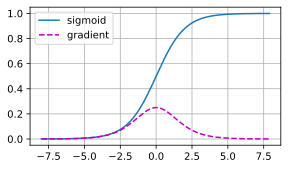

In [ ]:
# Tạo một tensor x chạy từ -8.0 đến 8.0 với bước nhảy 0.1 và bật tính năng tính gradient
x = torch.arange(-8.0, 8.0, 0.1, requires_grad=True)
# Áp dụng hàm kích hoạt sigmoid lên x
y = torch.sigmoid(x)
# Thực hiện lan truyền ngược để tính toán gradient
y.backward(torch.ones_like(x))

# Vẽ đồ thị biểu diễn hàm sigmoid và gradient của nó
d2l.plot(x.detach().numpy(), [y.detach().numpy(), x.grad.numpy()],
         legend=['sigmoid', 'gradient'], figsize=(4.5, 2.5))

Như bạn có thể thấy, (**gradient của hàm sigmoid biến mất (tiêu biến) cả khi đầu vào của nó rất lớn và khi chúng rất nhỏ**). Hơn nữa, khi lan truyền ngược qua nhiều lớp, trừ khi chúng ta ở trong vùng lý tưởng (Goldilocks zone) nơi đầu vào của nhiều hàm sigmoid gần bằng không, gradient của tích tổng thể có khả năng bị triệt tiêu. Khi mạng của chúng ta có nhiều lớp, nếu không cẩn thận, gradient rất có thể sẽ bị cắt đứt ở một lớp nào đó. Trên thực tế, vấn đề này từng gây khó khăn rất lớn cho việc huấn luyện mạng sâu. Do đó, ReLU - một hàm kích hoạt ổn định hơn (mặc dù ít giống sinh học hơn) - đã trở thành lựa chọn mặc định của các kỹ sư thực hành.


### [**Bùng nổ Gradient**]

Vấn đề ngược lại, khi các gradient bùng nổ, cũng có thể gây khó chịu không kém. Để minh họa điều này rõ hơn một chút, chúng ta tạo ra 100 ma trận ngẫu nhiên phân phối Gaussian và nhân chúng với một ma trận khởi đầu. Với tỷ lệ mà chúng ta đã chọn (lựa chọn phương sai $\sigma^2=1$), tích ma trận sẽ bùng nổ cực kỳ nhanh chóng. Khi điều này xảy ra do quá trình khởi tạo một mạng sâu, chúng ta hoàn toàn không có cơ hội làm cho thuật toán tối ưu hóa giảm độ dốc (gradient descent) hội tụ.

In [ ]:
# Khởi tạo một ma trận ngẫu nhiên phân phối chuẩn cỡ 4x4
M = torch.normal(0, 1, size=(4, 4))
print('Ma trận ban đầu: \n', M)

# Nhân ma trận này liên tiếp 100 lần với các ma trận ngẫu nhiên khác
for i in range(100):
    M = M @ torch.normal(0, 1, size=(4, 4))
print('Sau khi nhân 100 ma trận liên tiếp:\n', M)
# Bạn sẽ thấy giá trị của ma trận đầu ra cực kỳ lớn (bùng nổ số học)

a single matrix 
 tensor([[-0.8755, -1.2171,  1.3316,  0.1357],
        [ 0.4399,  1.4073, -1.9131, -0.4608],
        [-2.1420,  0.3643, -0.5267,  1.0277],
        [-0.1734, -0.7549,  2.3024,  1.3085]])
after multiplying 100 matrices
 tensor([[-2.9185e+23,  1.3915e+25, -1.1865e+25,  1.4354e+24],
        [ 4.9142e+23, -2.3430e+25,  1.9979e+25, -2.4169e+24],
        [ 2.6578e+23, -1.2672e+25,  1.0805e+25, -1.3072e+24],
        [-5.2223e+23,  2.4899e+25, -2.1231e+25,  2.5684e+24]])


### Phá vỡ tính đối xứng (Breaking the Symmetry)

Một vấn đề khác trong thiết kế mạng thần kinh là tính đối xứng vốn có trong cách tham số hóa của chúng. Giả sử chúng ta có một mô hình MLP đơn giản với một lớp ẩn và hai đơn vị (hidden units). Trong trường hợp này, chúng ta có thể hoán vị các trọng số $\mathbf{W}^{(1)}$ của lớp thứ nhất và tương tự hoán vị các trọng số của lớp đầu ra để thu được cùng một hàm số. Không có gì đặc biệt để phân biệt giữa đơn vị ẩn thứ nhất và thứ hai. Nói cách khác, chúng ta có tính đối xứng hoán vị (permutation symmetry) giữa các đơn vị ẩn của mỗi lớp.

Đây không chỉ là một rắc rối mang tính lý thuyết. Hãy xem xét mô hình MLP một lớp ẩn có hai đơn vị ẩn nói trên. Để minh họa, giả sử rằng lớp đầu ra biến đổi hai đơn vị ẩn thành chỉ một đơn vị đầu ra. Hãy tưởng tượng điều gì sẽ xảy ra nếu chúng ta khởi tạo tất cả các tham số của lớp ẩn dưới dạng $\mathbf{W}^{(1)} = c$ với một hằng số $c$ nào đó. Trong trường hợp này, trong quá trình lan truyền xuôi, cả hai đơn vị ẩn đều nhận cùng một đầu vào và tham số, tạo ra cùng một giá trị kích hoạt được truyền tới đơn vị đầu ra. Trong quá trình lan truyền ngược, việc đạo hàm đơn vị đầu ra đối với các tham số $\mathbf{W}^{(1)}$ sẽ cho ra một gradient mà tất cả các phần tử đều có cùng một giá trị. Do đó, sau các bước lặp dựa trên gradient (ví dụ: hạ dốc gradient ngẫu nhiên theo mini-batch - SGD), tất cả các phần tử của $\mathbf{W}^{(1)}$ vẫn có cùng một giá trị như nhau. Những lần lặp như vậy sẽ không bao giờ *tự phá vỡ tính đối xứng* và chúng ta có thể không bao giờ khai thác được sức mạnh biểu đạt của mạng. Lớp ẩn sẽ hoạt động như thể nó chỉ có một đơn vị duy nhất. Lưu ý rằng mặc dù thuật toán SGD thông thường không phá vỡ tính đối xứng này, nhưng phương pháp điều chuẩn Dropout (sẽ được giới thiệu sau) thì có thể!


## Khởi tạo Tham số (Parameter Initialization)

Một cách để giải quyết—hoặc ít nhất là giảm bớt—các vấn đề nêu trên là thông qua việc khởi tạo tham số một cách cẩn thận. Như chúng ta sẽ thấy sau này, việc chăm chút thêm trong quá trình tối ưu hóa và áp dụng các phương pháp điều chuẩn phù hợp có thể tăng cường độ ổn định hơn nữa.


### Khởi tạo mặc định (Default Initialization)

Trong các phần trước, ví dụ như trong :numref:`sec_linear_concise`, chúng ta đã sử dụng phân phối chuẩn để khởi tạo giá trị của các trọng số. Nếu chúng ta không chỉ định phương pháp khởi tạo cụ thể, framework sẽ sử dụng phương pháp khởi tạo ngẫu nhiên mặc định, phương pháp này thường hoạt động tốt trong thực tế cho các bài toán có kích thước vừa phải.


### Khởi tạo Xavier (Xavier Initialization)
:label:`subsec_xavier`

Hãy xem xét phân phối quy mô của một đầu ra $o_{i}$ cho một lớp liên kết đầy đủ (fully connected) *không có các hàm phi tuyến tính*. Với $n_\textrm{in}$ đầu vào $x_j$ và các trọng số liên kết tương ứng $w_{ij}$ của lớp này, một đầu ra được tính bằng:

$$o_{i} = \sum_{j=1}^{n_\textrm{in}} w_{ij} x_j.$$

Các trọng số $w_{ij}$ đều được rút ra một cách độc lập từ cùng một phân phối. Hơn nữa, hãy giả định rằng phân phối này có kỳ vọng bằng 0 và phương sai $\sigma^2$. Lưu ý rằng điều này không có nghĩa là phân phối bắt buộc phải là Gaussian, chỉ cần kỳ vọng và phương sai tồn tại là được. Hiện tại, hãy giả định rằng các đầu vào của lớp $x_j$ cũng có kỳ vọng bằng 0 và phương sai $\gamma^2$, đồng thời chúng độc lập với $w_{ij}$ và độc lập với nhau. Trong trường hợp này, chúng ta có thể tính kỳ vọng của $o_i$:

$$
\begin{aligned}
    E[o_i] & = \sum_{j=1}^{n_\textrm{in}} E[w_{ij} x_j] \\&= \sum_{j=1}^{n_\textrm{in}} E[w_{ij}] E[x_j] \\&= 0, \end{aligned}$$

và phương sai:

$$
\begin{aligned}
    \textrm{Var}[o_i] & = E[o_i^2] - (E[o_i])^2 \\
        & = \sum_{j=1}^{n_\textrm{in}} E[w^2_{ij} x^2_j] - 0 \\
        & = \sum_{j=1}^{n_\textrm{in}} E[w^2_{ij}] E[x^2_j] \\
        & = n_\textrm{in} \sigma^2 \gamma^2.
\end{aligned}
$$

Một cách để giữ cho phương sai không đổi là đặt $n_\textrm{in} \sigma^2 = 1$. Bây giờ hãy xem xét quá trình lan truyền ngược. Ở đó chúng ta đối mặt với một vấn đề tương tự, mặc dù với các gradient được lan truyền từ các lớp gần đầu ra hơn. Sử dụng lập luận tương tự như đối với lan truyền xuôi, chúng ta thấy rằng phương sai của các gradient có thể bùng nổ trừ khi $n_\textrm{out} \sigma^2 = 1$, trong đó $n_\textrm{out}$ là số lượng đầu ra của lớp này. Điều này đẩy chúng ta vào một tình thế tiến thoái lưỡng nan: chúng ta không thể thỏa mãn đồng thời cả hai điều kiện cùng một lúc. Thay vào đó, chúng ta cố gắng thỏa mãn điều kiện dung hòa:

$$
\begin{aligned}
\frac{1}{2} (n_\textrm{in} + n_\textrm{out}) \sigma^2 = 1 \textrm{ hoặc tương đương }
\sigma = \sqrt{\frac{2}{n_\textrm{in} + n_\textrm{out}}}.
\end{aligned}
$$

Đây là lập luận nền tảng cho phương pháp khởi tạo *Xavier* tiêu chuẩn và cực kỳ hữu ích trên thực tế, được đặt theo tên của tác giả đầu tiên sáng tạo ra nó :cite:`Glorot.Bengio.2010`. Thông thường, phương pháp khởi tạo Xavier lấy mẫu các trọng số từ phân phối Gaussian với trung bình bằng không và phương sai $\sigma^2 = \frac{2}{n_\textrm{in} + n_\textrm{out}}$. Chúng ta cũng có thể điều chỉnh điều này để chọn phương sai khi lấy mẫu trọng số từ một phân phối đều. Lưu ý rằng phân phối đều $U(-a, a)$ có phương sai là $\frac{a^2}{3}$. Thay thế $\frac{a^2}{3}$ vào điều kiện của $\sigma^2$ dẫn chúng ta đến việc khởi tạo theo phân phối:

$$U\left(-\sqrt{\frac{6}{n_\textrm{in} + n_\textrm{out}}}, \sqrt{\frac{6}{n_\textrm{in} + n_\textrm{out}}}\right).$$

Mặc dù giả định về việc không tồn tại các hàm phi tuyến trong các suy luận toán học trên có thể dễ dàng bị vi phạm trong các mạng thần kinh thực tế, nhưng phương pháp khởi tạo Xavier vẫn tỏ ra hoạt động rất hiệu quả trong thực tiễn.


### Đi xa hơn nữa (Beyond)

Các lập luận toán học ở trên mới chỉ chạm đến bề nổi của các phương pháp tiếp cận hiện đại trong việc khởi tạo tham số. Một thư viện học sâu thường triển khai hơn mười phương pháp phỏng đoán khác nhau. Hơn nữa, khởi tạo tham số tiếp tục là một chủ đề nghiên cứu cơ bản rất nóng trong lĩnh vực học sâu. Trong số đó có các phương pháp phỏng đoán chuyên biệt cho các tham số ràng buộc (chia sẻ chung), siêu phân giải (super-resolution), các mô hình dạng chuỗi (sequence models) và các tình huống khác. Ví dụ, :citet:`Xiao.Bahri.Sohl-Dickstein.ea.2018` đã chứng minh khả năng huấn luyện các mạng thần kinh lên đến 10,000 lớp mà không cần các mẹo kiến trúc phức tạp bằng cách sử dụng phương pháp khởi tạo được thiết kế vô cùng tỉ mỉ.

Nếu chủ đề này làm bạn hứng thú, chúng tôi khuyên bạn nên đi sâu vào các tài liệu tham khảo của module này, đọc các bài báo đề xuất và phân tích từng phương pháp phỏng đoán, rồi sau đó khám phá các công bố mới nhất về chủ đề này. Biết đâu bạn sẽ tình cờ tìm thấy hoặc thậm chí phát minh ra một ý tưởng thông minh và đóng góp một bản triển khai cho các thư viện học sâu.


## Tóm tắt

* Tiêu biến và bùng nổ gradient là các vấn đề phổ biến trong các mạng sâu. Cần hết sức cẩn thận trong việc khởi tạo tham số để đảm bảo rằng các gradient và tham số được kiểm soát tốt.
* Các phương pháp phỏng đoán khởi tạo là cần thiết để đảm bảo rằng các gradient ban đầu không quá lớn cũng không quá nhỏ.
* Khởi tạo ngẫu nhiên là chìa khóa để đảm bảo tính đối xứng bị phá vỡ trước khi thực hiện tối ưu hóa.
* Khởi tạo Xavier đề xuất rằng, đối với mỗi lớp, phương sai của bất kỳ đầu ra nào không bị ảnh hưởng bởi số lượng đầu vào và phương sai của bất kỳ gradient nào không bị ảnh hưởng bởi số lượng đầu ra.
* Hàm kích hoạt ReLU giúp giảm thiểu vấn đề tiêu biến gradient. Điều này giúp đẩy nhanh tốc độ hội tụ.

## Bài tập

1. Bạn có thể thiết kế các trường hợp khác mà mạng thần kinh có thể thể hiện tính đối xứng cần phá vỡ, bên ngoài tính đối xứng hoán vị trong các lớp của MLP không?
1. Chúng ta có thể khởi tạo tất cả các tham số trọng số trong hồi quy tuyến tính hoặc hồi quy softmax về cùng một giá trị không?
1. Hãy tra cứu các giới hạn giải tích về trị riêng của tích hai ma trận. Điều này cho bạn biết gì về việc đảm bảo các gradient có điều kiện tốt?
1. Nếu biết một số số hạng bị phân kỳ, chúng ta có thể khắc phục điều này sau khi sự việc đã xảy ra không? Hãy xem bài báo về layerwise adaptive rate scaling (LARS) để lấy cảm hứng :cite:`You.Gitman.Ginsburg.2017`.

[Thảo luận](https://discuss.d2l.ai/t/104)